# Setup

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as norm
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

%matplotlib inline

In [ ]:
# data_path = "../data/all_reviews.csv"

In [ ]:
# raw_df = pd.read_csv(data_path)

In [ ]:
# target_cols = ["Career Opportunities", "Compensation and Benefits", "Senior Management", "Work/Life Balance"]
# for c in target_cols:
#   raw_df[c] = pd.to_numeric(raw_df[c], errors="coerce")

In [ ]:
data_path2 = "../data/all_reviews.parquet"

df = pd.read_parquet(data_path2)

# Exploratory Data Analysis
## 1. Data Check

In [ ]:
print(f"Row: {len(df)} / Column: {len(df.columns)}")

Row: 9901889 / Column: 19


In [ ]:
print(df.dtypes)

rating                       float64
title                         object
status                        object
pros                          object
cons                          object
advice                        object
Recommend                     object
CEO Approval                  object
Business Outlook              object
Career Opportunities         float64
Compensation and Benefits    float64
Senior Management            float64
Work/Life Balance            float64
Culture & Values             float64
Diversity & Inclusion        float64
firm_link                     object
date                          object
job                           object
index                        float64
dtype: object


In [ ]:
print(df.head(1))

   rating title                                status  \
0     5.0  Good  Current Employee, more than 10 years   

                                  pros                                   cons  \
0  Knowledge gain of complete  project  Financial growth  and personal growth   

  advice Recommend CEO Approval Business Outlook  Career Opportunities  \
0   None         v            o                v                   3.0   

   Compensation and Benefits  Senior Management  Work/Life Balance  \
0                        3.0                3.0                3.0   

   Culture & Values  Diversity & Inclusion  \
0               3.0                    3.0   

                                           firm_link           date  \
0  Reviews/Baja-Steel-and-Fence-Reviews-E5462645.htm  Nov 19, 2022    

               job  index  
0   Manager Design    NaN  


In [ ]:
# The ratio of missing value
for col in df.columns:
    print(f"{col:<30}{(df[col].isnull().sum() / len(df))*100:>10.2f}%")

rating                              0.00%
title                               0.40%
status                              0.00%
pros                                0.00%
cons                                0.00%
advice                            100.00%
Recommend                           0.00%
CEO Approval                        0.00%
Business Outlook                    0.00%
Career Opportunities               19.49%
Compensation and Benefits          20.19%
Senior Management                  20.59%
Work/Life Balance                  20.17%
Culture & Values                   22.69%
Diversity & Inclusion              66.09%
firm_link                           0.00%
date                                0.00%
job                                 0.00%
index                              98.37%


In [ ]:
# The number of duplicated values
for col in df.columns:
    print(f"{col:<30}{str(df[col].duplicated().sum()):>10}")

rating                           9901883
title                            6312385
status                           9901793
pros                             1502740
cons                             1473136
advice                           9901875
Recommend                        9901885
CEO Approval                     9901884
Business Outlook                 9901884
Career Opportunities             9901883
Compensation and Benefits        9901883
Senior Management                9901883
Work/Life Balance                9901883
Culture & Values                 9901883
Diversity & Inclusion            9901883
firm_link                        9866348
date                             9896276
job                              9461295
index                            9898858


## 2. Univariate Analysis

In [ ]:
df = df[["rating", "status", "pros", "cons", "Culture & Values", "firm_link", "date", "job"]].copy()

### Numerical Columns

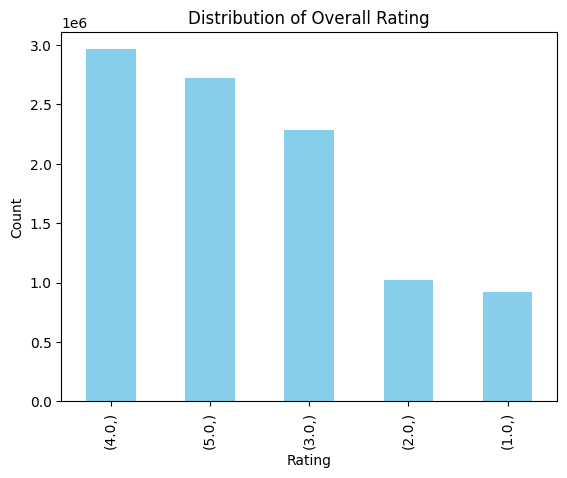

In [ ]:
# rating

df[["rating"]].value_counts().plot(kind='bar', color='skyblue')
plt.title("Distribution of Overall Rating")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

In [ ]:
print(f"Mean: {(df[['rating']].mean())}")
print(f"Median: {df[['rating']].median()}")
print(f"Standard Deviation: {df[['rating']].std()}")

Mean: rating    3.557778
dtype: float64
Median: rating    4.0
dtype: float64
Standard Deviation: rating    1.249354
dtype: float64


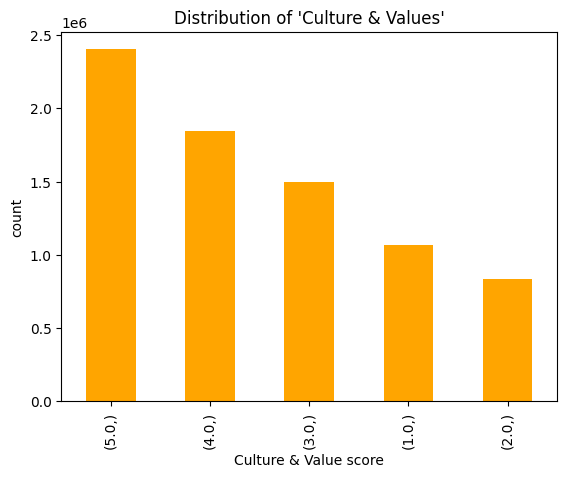

In [ ]:
# Culture & Values
df[["Culture & Values"]].value_counts().plot(kind='bar', color='orange')

plt.title("Distribution of 'Culture & Values'")
plt.xlabel("Culture & Value score")
plt.ylabel("count")
plt.show()

In [ ]:
print(f"Mean: {df[['Culture & Values']].mean()}")
print(f"Median: {df[['Culture & Values']].median()}")
print(f"Standard Deviation: {df[['Culture & Values']].std()}")

Mean: Culture & Values    3.481324
dtype: float64
Median: Culture & Values    4.0
dtype: float64
Standard Deviation: Culture & Values    1.389978
dtype: float64


### Categorical Columns

In [ ]:
# status
print(f"The number of unique categories: {len(df["status"].unique())}")

The number of unique categories: 96


In [ ]:
counts = df["status"].value_counts(sort=True)
print(counts)

status
Current Employee                                              2328379
Former Employee                                               1617824
Current Employee, more than 1 year                             974663
Former Employee, more than 1 year                              830200
Current Employee, more than 3 years                            730789
                                                               ...   
KEY NOT FOUND: jobLine.reserve-current, less than 1 year            1
Current PhD                                                         1
Current Temporary Employee, more than 5 years                       1
KEY NOT FOUND: jobLine.seasonal-current, more than 5 years          1
Formerly Self-employed, more than 1 year                            1
Name: count, Length: 95, dtype: int64


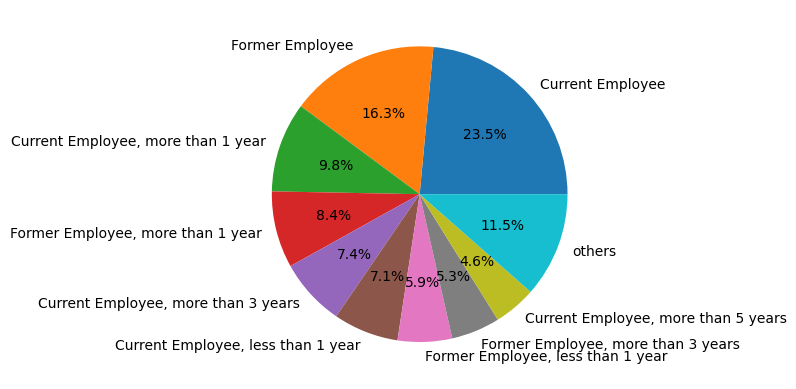

In [ ]:
labels = counts.index.to_series()
labels.iloc[9:] = "others"
counts.groupby(labels, sort=False).sum().plot(kind="pie", autopct='%1.1f%%')

plt.ylabel("")
plt.show()

### Date-time columns

In [ ]:
# date
print(df["date"].dtypes)

object


In [ ]:
df["date"] = pd.to_datetime(df["date"])
print(df["date"].dtypes)

datetime64[ns]


In [ ]:
print(f"Start Date: {df["date"].min()}")
print(f"End Date: {df["date"].max()}")
print(f"Duration: {df["date"].max() - df["date"].min()} days")

Start Date: 2008-01-25 00:00:00
End Date: 2023-07-26 00:00:00
Duration: 5661 days 00:00:00 days


date
2008.0      38358
2009.0      42916
2010.0      81826
2011.0     104395
2012.0     192190
2013.0     243981
2014.0     404973
2015.0     667439
2016.0     748514
2017.0     760680
2018.0     684241
2019.0     721680
2020.0     963670
2021.0    1959787
2022.0    1796544
2023.0     490524
Name: count, dtype: int64


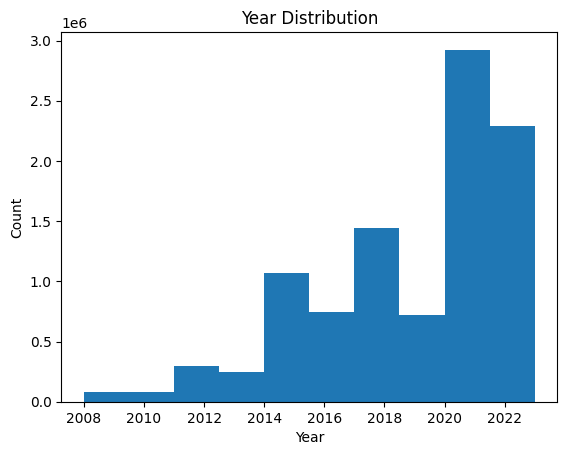

In [ ]:
print(df["date"].dt.year.value_counts().sort_index())

plt.hist(df["date"].dt.year)
plt.title("Year Distribution")
plt.ylabel("Count")
plt.xlabel("Year")
plt.show()

date
1.0     972268
2.0     906176
3.0     941396
4.0     795509
5.0     781066
6.0     784644
7.0     768262
8.0     829367
9.0     851296
10.0    863321
11.0    736292
12.0    672121
Name: count, dtype: int64


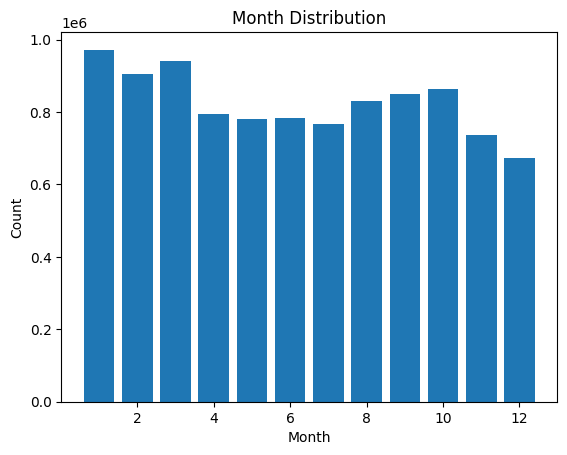

In [ ]:
print(df["date"].dt.month.value_counts().sort_index())

plt.hist(df["date"].dt.month, bins=np.arange(0.5, 13.5, 1), rwidth=0.8)
plt.title("Month Distribution")
plt.ylabel("Count")
plt.xlabel("Month")
plt.show()

In [ ]:
df["firm_id"] = df["firm_link"].str.extract(r"-Reviews-E(\d+)")[0]
df["number of reviews"] = df["firm_id"].map(df["firm_id"].value_counts())
print(df["number of reviews"].describe())
print(f"Number of firms: {df['firm_id'].nunique()}")
print(f"Missing firm_id: {df['firm_id'].isna().sum()}")

count    9.901889e+06
mean     1.423114e+04
std      2.547091e+04
min      1.000000e+00
25%      1.275000e+03
50%      4.390000e+03
75%      1.353400e+04
max      1.584920e+05
Name: number of reviews, dtype: float64
Number of firms: 35311
Missing firm_id: 0


In [ ]:
print(df["number of reviews"].head())

0     3
1     3
2     3
3    47
4    47
Name: number of reviews, dtype: int64


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


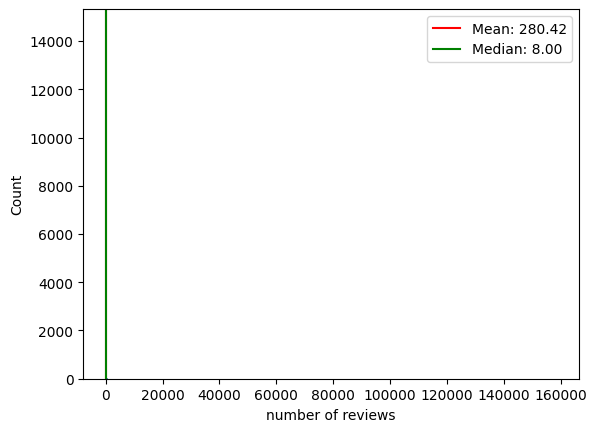

In [ ]:
# Histgram
firm_df = df.drop_duplicates("firm_id")
col = firm_df["number of reviews"]

mean = col.mean()
median = col.median()

sns.histplot(col)

plt.axvline(mean, color='red', label=f"Mean: {mean:.2f}")
plt.axvline(median, color='green', label=f"Median: {median:.2f}")

plt.legend()
plt.show()

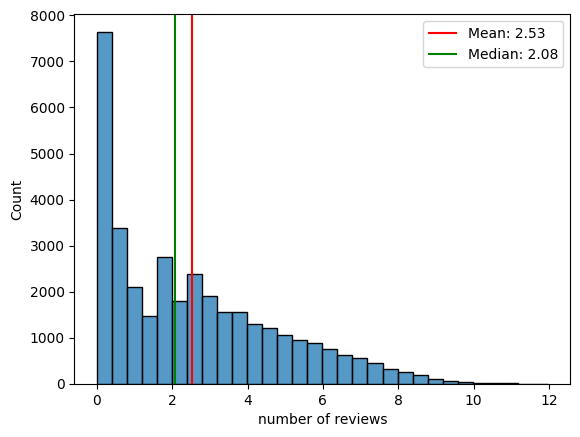

In [ ]:
# Log-scale
log_data = np.log(col)

log_mean = log_data.mean()
log_median = log_data.median()

sns.histplot(log_data, bins=30)

plt.axvline(log_mean, color='red', label=f"Mean: {log_mean:.2f}")
plt.axvline(log_median, color='green', label=f"Median: {log_median:.2f}")


plt.legend()
plt.show()

### Text data

In [ ]:
# Pros
df["pros_length"] = df["pros"].str.len()
df["cons_length"] = df["cons"].str.len()

print(f"Pros: {df["pros_length"].describe()} \nCons: {df["cons_length"].describe()}")

Pros: count    9.901701e+06
mean     8.743907e+01
std      1.105775e+02
min      1.000000e+00
25%      3.800000e+01
50%      5.300000e+01
75%      9.600000e+01
max      1.819300e+04
Name: pros_length, dtype: float64 
Cons: count    9.901655e+06
mean     1.247919e+02
std      2.349949e+02
min      1.000000e+00
25%      3.700000e+01
50%      5.700000e+01
75%      1.210000e+02
max      3.837900e+04
Name: cons_length, dtype: float64


In [ ]:
# Check short sentences
print(f"Short texts in the pros: {df["pros"][df["pros_length"] <= 10].head()}\n")
print(f"Short texts in the cons: {df["cons"][df["cons_length"] <= 10].head()}")

Short texts in the pros: 43733     b r e a k
70963     * * * * *
346804    . . . . .
396750    - - - - -
455548     All good
Name: pros, dtype: object

Short texts in the cons: 1118      No Cons
1345     pay rate
10565        none
12750        none
16391     Nothing
Name: cons, dtype: object


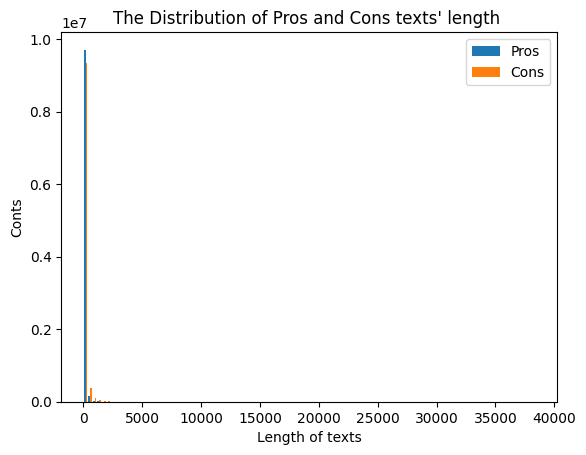

In [ ]:
plt.hist((df[["pros_length", "cons_length"]]), bins=100, label=["Pros", "Cons"])

plt.title("The Distribution of Pros and Cons texts' length ")
plt.xlabel("Length of texts")
plt.ylabel("Conts")

plt.legend()
plt.show()

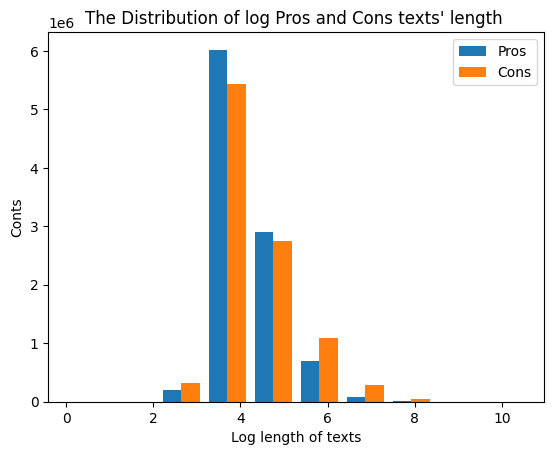

In [ ]:
plt.hist(np.log(df[["pros_length", "cons_length"]]), label=["Pros", "Cons"])

plt.title("The Distribution of log Pros and Cons texts' length ")
plt.xlabel("Log length of texts")
plt.ylabel("Conts")

plt.legend()
plt.show()

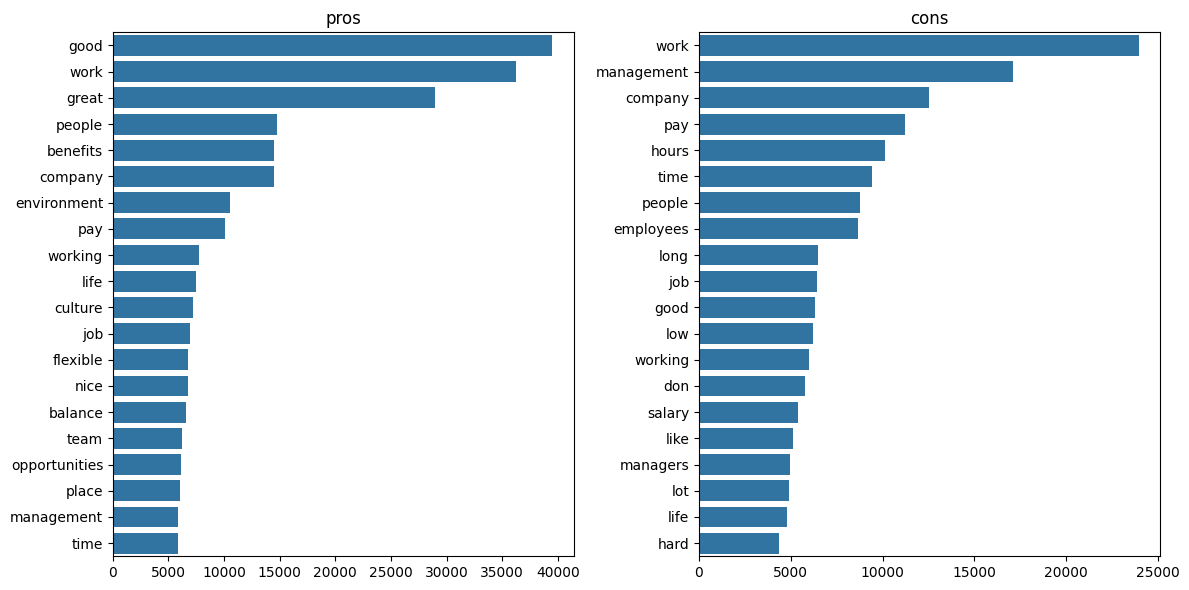

In [ ]:
# Investigate frequent words
sample = df.sample(100_000, random_state=507)

def top_words(series, n=20):
    counter = Counter()
    for tokens in series.dropna().str.lower().str.findall(r"[a-z]+"):
        counter.update(w for w in tokens if len(w) > 1 and w not in ENGLISH_STOP_WORDS)
    return counter.most_common(n)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, col in zip(axes, ["pros", "cons"]):
    words, counts = zip(*top_words(sample[col]))
    sns.barplot(x=list(counts), y=list(words), ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()